# Libs

In [1]:
import os
import json
import re
import io
import soundfile as sf
import random
from collections import OrderedDict
import math

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import glob
import pickle
import tqdm
import kagglehub

In [4]:
from datasets import load_dataset
from datasets import Features, Audio, Value

In [5]:
import librosa
from IPython.display import Audio as AudioPlayer, display

In [6]:
from huggingface_hub import login
from huggingface_hub import whoami
from kaggle_secrets import UserSecretsClient

In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import normalize
from sklearn.manifold import TSNE

# Tokens

In [8]:
login( UserSecretsClient().get_secret("HF_2") )

In [9]:
print(whoami()['name'])

yosef-samy019


# Constants

In [10]:
MEL_PINS_PATH = 'mel_pins.json'

In [11]:
AUDIO_SR = 20_000
AUDIO_N_FFT = 2048
AUDIO_N_MELS = 128
AUDIO_HOP_LENGTH = 256
AUDIO_WINDOW_TYPE = 'hann'

In [12]:
N_CLUSTERS = 3_072

CLUSTER_DICT_PATH = "clusters_points.json"

# Functions

In [13]:
def pkl_save_obj(obj, file_name):
    with open(file_name, 'wb') as f:
        pickle.dump(obj, f)

def pkl_load_obj(file_name):
    with open(file_name, 'rb') as f:
        return pickle.load(f)

In [14]:
def json_save_obj(obj, file_name):
    with open(file_name, 'w', encoding='UTF+8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)

def json_load_obj(file_name):
    with open(file_name, 'r', encoding='UTF+8') as f:
        return json.load(f)

# Cache

In [15]:
json_save_obj(
    {
        "sample_rate": AUDIO_SR,
        "n_fft": AUDIO_N_FFT,
        "n_mels": AUDIO_N_MELS,
        "hop_length": AUDIO_HOP_LENGTH,
        "window_type": AUDIO_WINDOW_TYPE,
    },
    "config.json"
)

# Dataset Load

In [16]:
def download_da7ee7(max_samples = 10_000):
    os.makedirs("audios", exist_ok=True)
    # ------------------------
    # Load dataset in streaming mode
    # ------------------------
    ds_1 = load_dataset("oddadmix/da7ee7_sep_cleaned-8k", split="train", streaming=True)
    ds_1 = ds_1.cast_column("separated_target_audio", Audio(decode=False))

    loader_df = []
    count = 0

    for i, example in enumerate(tqdm.tqdm(ds_1)):
        if count >= max_samples:
            break

        try:
            audio_bytes = example['separated_target_audio']['bytes']
            text_content = example['normalized_text']

            # Read audio from bytes
            audio_data, samplerate = sf.read(io.BytesIO(audio_bytes))

            # Save locally
            full_path = os.path.join("audios", f"audio_{count:06d}.wav")
            sf.write(full_path, audio_data, samplerate)

            # Store info
            loader_df.append({
                "path": full_path,
                "text": text_content,
                "duration_s": len(audio_data) / samplerate
            })

            count += 1

        except Exception as e:
            print(f"Error at index {i}: {e}")

    print(f"Saved {len(loader_df)} samples to da7ee7_sep_cleaned")

    return loader_df

In [17]:
loader_df = pd.DataFrame(download_da7ee7())

README.md:   0%|          | 0.00/628 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/44 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/44 [00:00<?, ?it/s]

8000it [52:13,  2.55it/s]

Saved 8000 samples to da7ee7_sep_cleaned


In [18]:
loader_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   path        8000 non-null   object 
 1   text        8000 non-null   object 
 2   duration_s  8000 non-null   float64
dtypes: float64(1), object(2)
memory usage: 187.6+ KB


In [19]:
loader_df.head()

,path,text,duration_s
0,audios/audio_000000.wav,راح فين يا فندم؟ شفني بدوّر؟ احنا لقينا مارادو...,7.069333
1,audios/audio_000001.wav,"احنا لقينا ""مارادونا"" يا فندم، إيه؟ خير نوعت، ...",11.928000
2,audios/audio_000002.wav,وبكدا، مارادونا اعتز الكرة، أيه؟ وبقى يغنّي شع...,10.481333
3,audios/audio_000003.wav,بنفسك! ما تيجوا أرماندو مارادونا، اللي بدوّر ع...,9.866667
4,audios/audio_000004.wav,مين؟ شوف إزاي؟ بقى يغني شعبي، مش هسيبك، كمان ر...,11.721333


# Audio Loader

In [20]:
def load_audio(path: str):
    y, sr = librosa.load(path, sr=AUDIO_SR, mono=True)
    return y

/tmp/ipykernel_24/1363266002.py:3: FutureWarning: waveshow() keyword argument 'x_axis' has been renamed to 'axis' in version 0.10.0.
	This alias will be removed in version 1.0.
  librosa.display.waveshow(temp, sr=AUDIO_SR, x_axis='s')


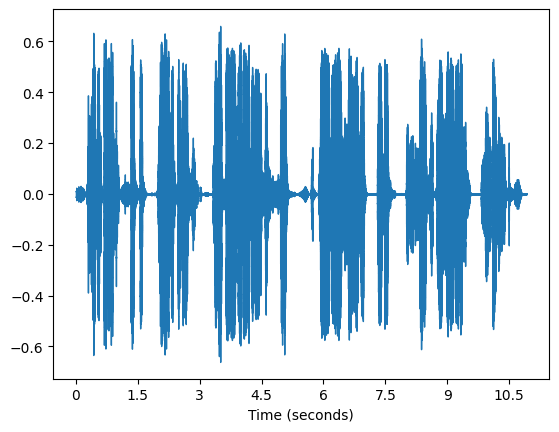

In [21]:
temp = load_audio(loader_df.iloc[6,0])

librosa.display.waveshow(temp, sr=AUDIO_SR, x_axis='s')

In [22]:
AudioPlayer(temp, rate=AUDIO_SR)

# Freq Domain

In [23]:
def audio_2_log_mel(audio_wave):
    mel_spectrogram = librosa.feature.melspectrogram(
        y=audio_wave,
        sr=AUDIO_SR,
        n_fft=AUDIO_N_FFT,
        hop_length=AUDIO_HOP_LENGTH,
        win_length=AUDIO_N_FFT,
        n_mels=AUDIO_N_MELS,
        window=AUDIO_WINDOW_TYPE
    )
    log_mel = librosa.power_to_db(mel_spectrogram, ref=np.max)

    # Clip: [-80 -> 0]
    max_v = 0
    min_v = -80

    clipped_log_mel = np.clip(log_mel, min_v, max_v)

    return clipped_log_mel

In [24]:
def log_mel_2_audio(log_mel):
    # Convert back to power (dB -> amplitude)
    mel_spec = librosa.db_to_power(log_mel)

    # Invert Mel spectrogram to audio
    y = librosa.feature.inverse.mel_to_audio(
        M=mel_spec,
        sr=AUDIO_SR,
        n_fft=AUDIO_N_FFT,
        hop_length=AUDIO_HOP_LENGTH,
        win_length=AUDIO_N_FFT,
        window=AUDIO_WINDOW_TYPE,
    )

    return y.astype(np.float32)

Min: -80.0
Max: 0.0
Shape: (128, 819)


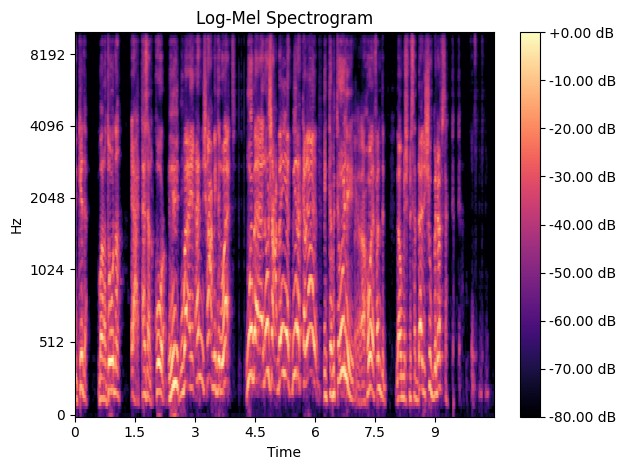

In [25]:
temp_freq = audio_2_log_mel(load_audio(loader_df.iloc[2,0]))

print("Min:", np.min(temp_freq))
print("Max:", np.max(temp_freq))
print("Shape:", temp_freq.shape)


librosa.display.specshow(temp_freq, sr=AUDIO_SR, hop_length=AUDIO_HOP_LENGTH,
                         x_axis='time', y_axis='mel')

plt.colorbar(format='%+2.2f dB')
plt.title('Log-Mel Spectrogram')
plt.tight_layout()
plt.show()

## Test

In [26]:
temp_audio = load_audio(loader_df.iloc[4,0])

In [27]:
AudioPlayer(temp_audio, rate=AUDIO_SR)

Log Mel Shape: (128, 916)


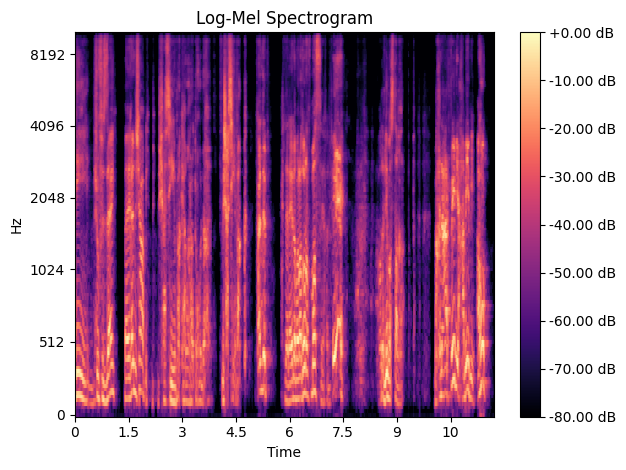

In [28]:
temp_log_mel = audio_2_log_mel(temp_audio)

librosa.display.specshow(temp_log_mel, sr=AUDIO_SR, hop_length=AUDIO_HOP_LENGTH,
                         x_axis='time', y_axis='mel')

print("Log Mel Shape:", temp_log_mel.shape)

plt.colorbar(format='%+2.2f dB')
plt.title('Log-Mel Spectrogram')
plt.tight_layout()
plt.show()

In [29]:
reconstrucrted_audio = log_mel_2_audio(temp_log_mel)
AudioPlayer(reconstrucrted_audio, rate=AUDIO_SR)

# Mel Pins Clustering

In [30]:
loader_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   path        8000 non-null   object 
 1   text        8000 non-null   object 
 2   duration_s  8000 non-null   float64
dtypes: float64(1), object(2)
memory usage: 187.6+ KB


## Get all pins matrix

In [31]:
pins_matrix = []

for i in tqdm.tqdm(range(len(loader_df))):
  audio_path = loader_df.loc[i,'path']
  audio_series = load_audio(audio_path)
  log_mel = audio_2_log_mel(audio_series)
  transverse_log_mel = np.transpose(log_mel)
  pins_matrix.extend(list(transverse_log_mel))

100%|██████████| 8000/8000 [04:14<00:00, 31.38it/s]


In [32]:
pins_matrix = np.array(pins_matrix)
pins_matrix.shape

(6999156, 128)

## Clustering

In [33]:
class AudioKMeansQuantizer:
    def __init__(
        self,
        n_clusters: int,
        max_iter: int,
        n_init: int,
        random_state: int = 42,
        verbose: int = 1,
    ):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.n_init = n_init
        self.random_state = random_state
        self.verbose = verbose

        self.model = None
        self.centroids = None

    def fit(self, X: np.ndarray):
        X_norm = normalize(X) # For cosine similarity

        batch_size = max(1000, int(0.45 * len(X_norm)))

        self.model = MiniBatchKMeans(
            n_clusters=self.n_clusters,
            batch_size=batch_size,
            max_iter=self.max_iter,
            n_init=self.n_init,
            random_state=self.random_state,
            verbose=self.verbose,
        )

        self.model.fit(X_norm)

        labels = self.model.predict(X_norm)

        centroids = np.zeros((self.n_clusters, X.shape[1]), dtype=X.dtype)

        for k in range(self.n_clusters):
            cluster_points = X[labels == k]
            if len(cluster_points) > 0:
                centroids[k] = cluster_points.mean(axis=0)

        self.centroids = centroids

        return self.centroids

    def predict(self, X: np.ndarray):
        X_norm = normalize(X)
        return self.model.predict(X_norm)

    def get_centroids(self):
        return self.centroids

In [34]:
cluster_model = AudioKMeansQuantizer(
    n_clusters=N_CLUSTERS,
    max_iter=2_000,
    n_init=2,
)

cluster_model.fit(pins_matrix) 

Init 1/2 with method k-means++
Inertia for init 1/2: 99658.96875
Init 2/2 with method k-means++
Inertia for init 2/2: 99784.921875
[MiniBatchKMeans] Reassigning 139 cluster centers.
Minibatch step 1/4444: mean batch inertia: 0.014243680090772854
[MiniBatchKMeans] Reassigning 138 cluster centers.
Minibatch step 2/4444: mean batch inertia: 0.01112321932883967, ewa inertia: 0.01112321932883967
[MiniBatchKMeans] Reassigning 119 cluster centers.
Minibatch step 3/4444: mean batch inertia: 0.010989285761060064, ewa inertia: 0.011002679142714397
[MiniBatchKMeans] Reassigning 113 cluster centers.
Minibatch step 4/4444: mean batch inertia: 0.010944644959153803, ewa inertia: 0.010950448388288939
[MiniBatchKMeans] Reassigning 108 cluster centers.
Minibatch step 5/4444: mean batch inertia: 0.010912959589172662, ewa inertia: 0.010916708476047334
[MiniBatchKMeans] Reassigning 102 cluster centers.
Minibatch step 6/4444: mean batch inertia: 0.010888156249801563, ewa inertia: 0.010891011477729334
[MiniB

array([[-70.837204, -69.75963 , -65.27341 , ..., -74.06952 , -75.8123  ,
        -78.37575 ],
       [-60.894108, -55.036697, -45.765835, ..., -56.06757 , -61.4257  ,
        -72.687035],
       [-56.128696, -47.596207, -40.986786, ..., -75.14128 , -77.95727 ,
        -79.827065],
       ...,
       [-58.202007, -58.774593, -55.98281 , ..., -58.534252, -64.663025,
        -74.95571 ],
       [-73.41438 , -77.036446, -75.48911 , ..., -77.6617  , -78.54931 ,
        -79.52194 ],
       [-57.517246, -51.687397, -39.19656 , ..., -78.5578  , -79.483795,
        -79.94301 ]], dtype=float32)

## Save Clusters

In [35]:
centroids = cluster_model.get_centroids()
print(centroids.shape)

(3072, 128)


In [36]:
centroids_dict = {}

for i , point in enumerate(list(centroids)):
  centroids_dict[f"pin_{i:04d}"] = point.tolist()

In [37]:
json_save_obj(centroids_dict, CLUSTER_DICT_PATH)

## Visuals

In [38]:
plt.style.use(plt.style.available[12])

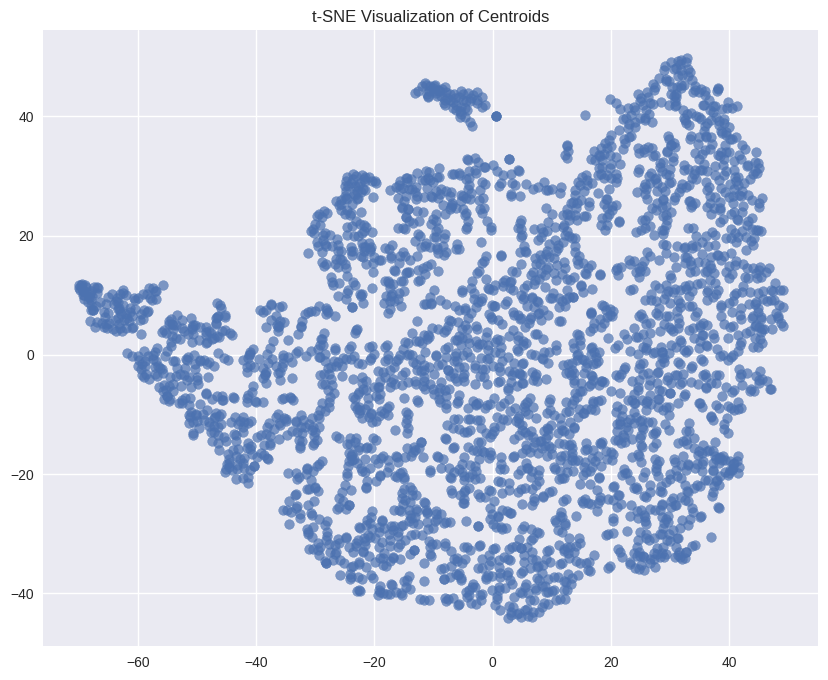

In [39]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(centroids)

plt.figure(figsize=(10, 8))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], alpha=0.7)
plt.title("t-SNE Visualization of Centroids")
plt.show()

## LogMel 2 Centroids

In [40]:
def quantize_log_mel(log_mel):
  transverse_log_mel = np.transpose(log_mel)
  centroids_idx = cluster_model.predict(transverse_log_mel)

  quantized_transverse_log_mel = [
      centroids_dict[f"pin_{x:04d}"] for x in centroids_idx
  ]

  quantized_log_mel = np.array(quantized_transverse_log_mel).T

  return quantized_log_mel

In [41]:
def log_mel_pins_name(log_mel):
  transverse_log_mel = np.transpose(log_mel)
  centroids_idx = cluster_model.predict(transverse_log_mel)

  pins = [
      f"pin_{x:04d}" for x in centroids_idx
  ]

  return pins

## Test

In [42]:
def pipe_test(audio_path):
  temp_audio = load_audio(audio_path)
  temp_log_mel = audio_2_log_mel(temp_audio)
  temp_recon_audio = log_mel_2_audio(temp_log_mel)
  temp_quantized_recon_log_mel = quantize_log_mel(temp_log_mel)
  temp_recon_quan_audio = log_mel_2_audio(temp_quantized_recon_log_mel)

  print("Orig Log Mel:", temp_log_mel.shape)
  print("Recon Quan Log Mel:", temp_quantized_recon_log_mel.shape)
  print("MAE(log mel):", np.mean(np.abs(temp_log_mel - temp_quantized_recon_log_mel)))
  print("Pins (first 40 pin...):", log_mel_pins_name(temp_log_mel)[:40])

  print("Original Audio")
  display(AudioPlayer(temp_audio, rate=AUDIO_SR))

  print("Original Audio -> Log Mel -> Audio")
  display(AudioPlayer(temp_recon_audio, rate=AUDIO_SR))

  print("Original Audio -> Log Mel -> Quantized Log Mel -> Audio")
  display(AudioPlayer(temp_recon_quan_audio, rate=AUDIO_SR))

  plt.figure(figsize=(15, 5))

  plt.subplot(1,3,1)
  librosa.display.specshow(temp_log_mel, sr=AUDIO_SR, hop_length=AUDIO_HOP_LENGTH,
                          x_axis='time', y_axis='mel')
  plt.title('Original Spectrogram')
  plt.tight_layout()


  plt.subplot(1,3,2)
  librosa.display.specshow(temp_quantized_recon_log_mel, sr=AUDIO_SR, hop_length=AUDIO_HOP_LENGTH,
                          x_axis='time', y_axis='mel')
  plt.title('Quantized Spectrogram')
  plt.tight_layout()

  plt.subplot(1,3,3)
  librosa.display.specshow(np.abs(temp_log_mel - temp_quantized_recon_log_mel), sr=AUDIO_SR, hop_length=AUDIO_HOP_LENGTH,
                          x_axis='time', y_axis='mel')
  plt.colorbar(format='%+2.2f dB')
  plt.title('Absolute Error')
  plt.tight_layout()

  plt.show()

Orig Log Mel: (128, 814)
Recon Quan Log Mel: (128, 814)
MAE(log mel): 5.430018386311591
Pins (first 40 pin...): ['pin_2305', 'pin_2305', 'pin_2305', 'pin_2085', 'pin_2085', 'pin_2961', 'pin_2961', 'pin_2961', 'pin_2961', 'pin_0021', 'pin_0021', 'pin_0824', 'pin_0824', 'pin_0824', 'pin_0352', 'pin_0352', 'pin_0352', 'pin_0352', 'pin_0021', 'pin_0021', 'pin_1714', 'pin_1714', 'pin_1714', 'pin_1476', 'pin_1476', 'pin_2893', 'pin_0119', 'pin_0297', 'pin_1295', 'pin_1058', 'pin_0518', 'pin_1354', 'pin_2013', 'pin_0108', 'pin_1823', 'pin_2471', 'pin_2801', 'pin_2898', 'pin_2898', 'pin_1690']
Original Audio


Original Audio -> Log Mel -> Audio


Original Audio -> Log Mel -> Quantized Log Mel -> Audio


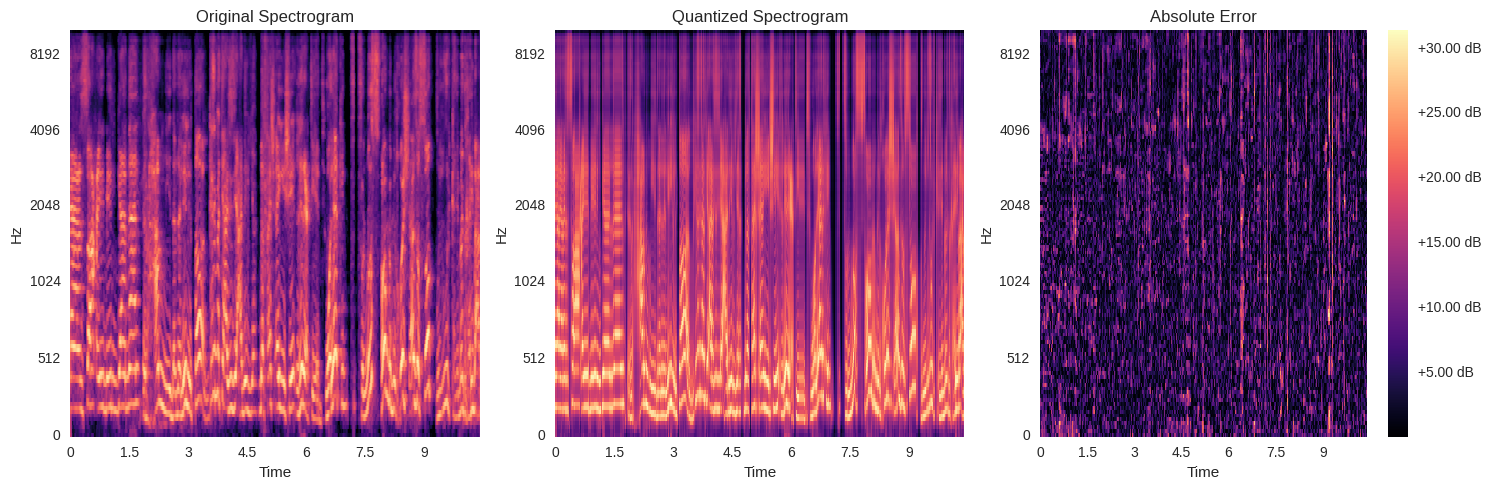

In [43]:
pipe_test(loader_df.loc[9, "path"])

Orig Log Mel: (128, 854)
Recon Quan Log Mel: (128, 854)
MAE(log mel): 5.087578936438545
Pins (first 40 pin...): ['pin_0415', 'pin_0415', 'pin_0415', 'pin_2003', 'pin_2363', 'pin_2363', 'pin_2363', 'pin_2363', 'pin_0265', 'pin_0265', 'pin_0265', 'pin_0265', 'pin_0265', 'pin_0265', 'pin_0265', 'pin_0265', 'pin_0742', 'pin_0210', 'pin_1922', 'pin_2816', 'pin_0635', 'pin_0635', 'pin_2563', 'pin_2160', 'pin_0579', 'pin_0090', 'pin_1904', 'pin_0579', 'pin_2160', 'pin_1162', 'pin_0227', 'pin_0227', 'pin_0227', 'pin_0227', 'pin_0227', 'pin_0227', 'pin_1748', 'pin_1748', 'pin_0235', 'pin_0235']
Original Audio


Original Audio -> Log Mel -> Audio


Original Audio -> Log Mel -> Quantized Log Mel -> Audio


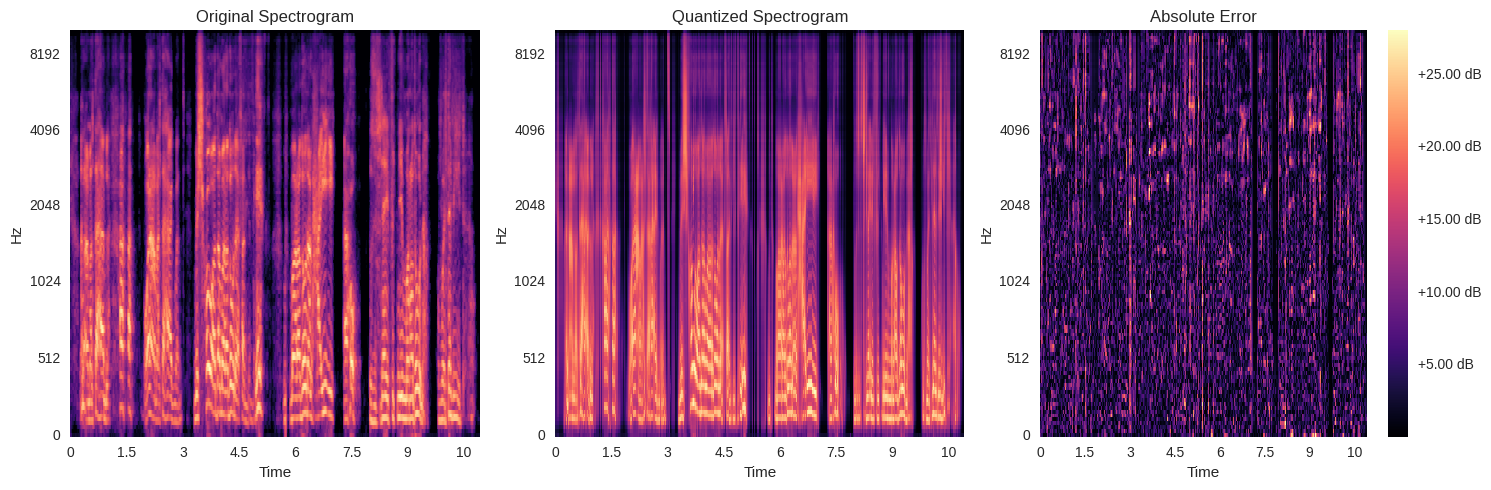

In [44]:
pipe_test(loader_df.loc[6, "path"])

Orig Log Mel: (128, 916)
Recon Quan Log Mel: (128, 916)
MAE(log mel): 5.101040041663859
Pins (first 40 pin...): ['pin_2521', 'pin_0480', 'pin_2083', 'pin_2040', 'pin_0631', 'pin_0885', 'pin_0952', 'pin_0952', 'pin_0952', 'pin_0952', 'pin_1453', 'pin_1453', 'pin_1453', 'pin_1453', 'pin_0970', 'pin_0970', 'pin_0970', 'pin_0095', 'pin_0095', 'pin_0095', 'pin_2527', 'pin_2527', 'pin_2527', 'pin_1993', 'pin_1993', 'pin_1993', 'pin_1762', 'pin_1762', 'pin_1762', 'pin_2827', 'pin_2827', 'pin_2827', 'pin_2218', 'pin_2580', 'pin_2580', 'pin_2580', 'pin_2580', 'pin_2580', 'pin_2580', 'pin_2580']
Original Audio


Original Audio -> Log Mel -> Audio


Original Audio -> Log Mel -> Quantized Log Mel -> Audio


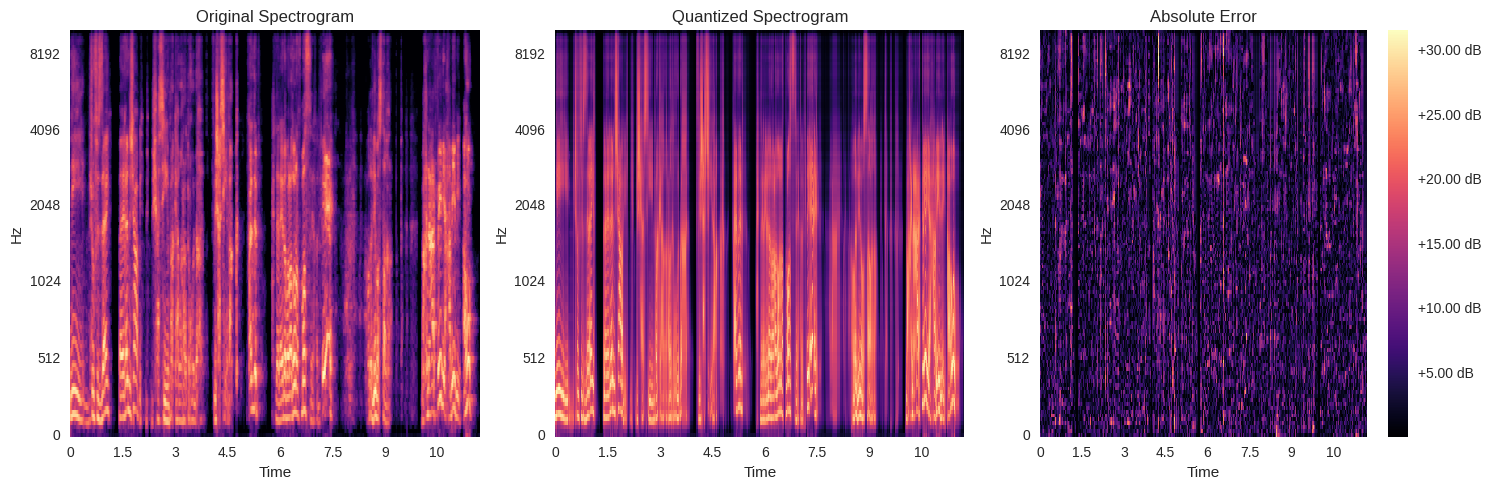

In [45]:
pipe_test(loader_df.loc[4, "path"])

# DataFrame

In [46]:
final_df = []

for i in tqdm.tqdm(range(len(loader_df))):
  audio_path = loader_df.loc[i,'path']
  audio_txt = loader_df.loc[i,'text']
  audio_duration = loader_df.loc[i,'duration_s']

  audio_series = load_audio(audio_path)
  log_mel = audio_2_log_mel(audio_series)
  centroids = log_mel_pins_name(log_mel)

  final_df.append({
      "path": audio_path,
      "text": audio_txt,
      "duration_s": audio_duration,
      "centroids": " ".join(centroids),
  })

final_df = pd.DataFrame(final_df)

100%|██████████| 8000/8000 [07:25<00:00, 17.97it/s]


In [47]:
final_df.loc[0, 'centroids']

'pin_0272 pin_0272 pin_0272 pin_0272 pin_0272 pin_0272 pin_1454 pin_2253 pin_1695 pin_1695 pin_1695 pin_1695 pin_1695 pin_1294 pin_1294 pin_1294 pin_0812 pin_0812 pin_1763 pin_1763 pin_0237 pin_0237 pin_0237 pin_2143 pin_2143 pin_0272 pin_0272 pin_0272 pin_0272 pin_0272 pin_0272 pin_1024 pin_0781 pin_0972 pin_1381 pin_2605 pin_1127 pin_1372 pin_2153 pin_0500 pin_0500 pin_2254 pin_3023 pin_2642 pin_2642 pin_2708 pin_2708 pin_2531 pin_2531 pin_0261 pin_0261 pin_0261 pin_1122 pin_2469 pin_2469 pin_2469 pin_0452 pin_0452 pin_2640 pin_2593 pin_2593 pin_1132 pin_2720 pin_2890 pin_1434 pin_0810 pin_0810 pin_1543 pin_1543 pin_2392 pin_2392 pin_1268 pin_2130 pin_2865 pin_2677 pin_2677 pin_2677 pin_0495 pin_1858 pin_1858 pin_1858 pin_1464 pin_1464 pin_1464 pin_1144 pin_1144 pin_1144 pin_1144 pin_1584 pin_1584 pin_0637 pin_0637 pin_0637 pin_0637 pin_0587 pin_0587 pin_0602 pin_0602 pin_0831 pin_0831 pin_1836 pin_0840 pin_0840 pin_0840 pin_0886 pin_0886 pin_2807 pin_2807 pin_0812 pin_1592 pin_1592 

In [48]:
final_df.to_csv(
    "data_table.csv",
    index=False)